# Analiza strezczeń literatury młodzieżowej

# import bibliotek

In [426]:
import os
import nltk
from nltk.corpus import PlaintextCorpusReader
import morfeusz2
from matplotlib import pyplot as plt
import operator as op
import string 
import itertools as it
from nltk.tokenize import word_tokenize
import pandas as pd
import json
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer
from wordcloud import WordCloud

In [427]:
nltk.pathsec.ENFORCE = False

# utworzenie korpusu dokumentów

In [428]:
corpus_dir = "./Literature"
nltk.data.path.append(corpus_dir)
nltk.download('punkt_tab')
corpus = PlaintextCorpusReader(corpus_dir,r'.*\.txt')
file_names= corpus.fileids()
print(file_names)


['Harry Potter i Czara Ognia.txt', 'Harry Potter i Insygnia Smierci.txt', 'Harry Potter i Kamien Filozoficzny.txt', 'Harry Potter i Komnata Tajemnic.txt', 'Harry Potter i Ksiaze Polkrwi.txt', 'Harry Potter i Przeklete Dziecko.txt', 'Harry Potter i Wiezien Azkabanu.txt', 'Harry Potter i Zakon Feniksa.txt', 'Opowiesci z Narni. Kon i jego chlopiec.txt', 'Opowiesci z Narni. Ksiaze Kaspian.txt', 'Opowiesci z Narni. Lew, czarownica i stara szafa.txt', 'Opowiesci z Narni. Ostatnia bitwa.txt', 'Opowiesci z Narni. Podroz Wedrowca do Switu.txt', 'Opowiesci z Narni. Siostrzeniec Czarodzieja.txt', 'Opowiesci z Narni. Srebrne krzeslo.txt', 'Zmierzch.Ksiezyc w Nowiu.txt', 'Zmierzch.Przed Switem.txt', 'Zmierzch.Zacmienie.txt', 'Zmierzch.Zmierzch.txt', 'Zmierzch.Zycie i Smierc.txt']


[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\48516\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


### zdefiniowanie funkcji pomocniczych

In [429]:
def print_dict(obj):
    print(json.dumps(obj , indent=4, ensure_ascii= False))

In [430]:
def create_dir(path):
    if not os.path.exists(path):
        os.mkdir(path)

In [431]:
document_dict = {}
for  file_name in file_names:
    document_dict[file_name] = corpus.raw(file_name)
print_dict(document_dict)

{
    "Harry Potter i Czara Ognia.txt": "Lord Voldemort, wraz ze swoim sługą Glizdogonem przybywa do domu należącego niegdyś do rodziny Riddle'ów położonego w Little Hangleton. Tam układają plan dotyczący zamordowania Harry'ego Pottera, co ma pomóc Czarnemu Panu w odzyskaniu jego dawnej mocy. Jest także mowa o wiernym słudze Czarnego Pana, który wkrótce ma znaleźć się w Hogwarcie. Wszystko to słyszy mieszkający nieopodal ogrodnik, Frank Bryce. Voldemort odkrywając, iż mężczyzna podsłuchuje, zaprasza go do środka i uśmierca. Harry budzi się z przerażającego snu. Jego blizna pulsuje okropnym bólem. Próbuje sobie przypomnieć o czym śnił, a z pamięci wyłania się obraz mrocznego pokoju, węża leżącego przed kominkiem oraz Glizdogona i Lorda Voldemorta planujących morderstwo. Harry zastanawia się czy powinien komuś powiedzieć o problemach z blizną, ponieważ, gdy bolała go ostatnim razem, Voldemort wdarł się do Hogwartu. Ostatecznie postanawia napisać do Syriusza i zejść na śniadanie. W trakci

In [432]:
lenghts = {}
for file_name in file_names:
    lenghts[file_name]={
        "pre": len(word_tokenize(document_dict[file_name])),
    }
print(json.dumps(lenghts, indent=4 ,ensure_ascii = False))
    
    

{
    "Harry Potter i Czara Ognia.txt": {
        "pre": 6748
    },
    "Harry Potter i Insygnia Smierci.txt": {
        "pre": 2997
    },
    "Harry Potter i Kamien Filozoficzny.txt": {
        "pre": 2236
    },
    "Harry Potter i Komnata Tajemnic.txt": {
        "pre": 1611
    },
    "Harry Potter i Ksiaze Polkrwi.txt": {
        "pre": 1993
    },
    "Harry Potter i Przeklete Dziecko.txt": {
        "pre": 3170
    },
    "Harry Potter i Wiezien Azkabanu.txt": {
        "pre": 2227
    },
    "Harry Potter i Zakon Feniksa.txt": {
        "pre": 1821
    },
    "Opowiesci z Narni. Kon i jego chlopiec.txt": {
        "pre": 179
    },
    "Opowiesci z Narni. Ksiaze Kaspian.txt": {
        "pre": 2376
    },
    "Opowiesci z Narni. Lew, czarownica i stara szafa.txt": {
        "pre": 2415
    },
    "Opowiesci z Narni. Ostatnia bitwa.txt": {
        "pre": 144
    },
    "Opowiesci z Narni. Podroz Wedrowca do Switu.txt": {
        "pre": 1155
    },
    "Opowiesci z Narni. Siostr

### utworzenie macierzy częstości

In [433]:
document_df_pre = pd.DataFrame.from_dict(document_dict, orient="index", columns=["content"])

In [434]:
cv =CountVectorizer
matrix_tf = cv().fit_transform(document_df['content'])
tv = TfidfVectorizer
matrix_tfidf =tv().fit_transform(document_df['content'])


In [435]:
sparsity_tf = (1 - (matrix_tf.nnz / (matrix_tf.shape[0] * matrix_tf.shape[1]))) * 100
sparsity_tfidf = ( 1 - (matrix_tfidf.nnz/ (matrix_tfidf.shape[0] * matrix_tfidf.shape[1])))* 100

In [436]:
matrices ={
    "pre": {
        "words": matrix_tf.shape[1],
        "sparsity":sparsity_tf
    }
}

# Wstępne przygotowanie dokumentów

In [437]:
stopwords_file = open("./stopwords_pl.txt", "r", encoding = "utf-8")
stopwords = stopwords_file.read().splitlines()
stopwords = stopwords[4:]
stopwords_file.close()
stopwords


['vol',
 'o.o.',
 'mgr',
 'godz',
 'zł',
 'www',
 'pl',
 'ul',
 'tel',
 'hab',
 'prof',
 'inż',
 'dr',
 'i',
 'u',
 'aby',
 'albo',
 'ale',
 'ani',
 'aż',
 'bardzo',
 'bez',
 'bo',
 'bowiem',
 'by',
 'byli',
 'bym',
 'był',
 'była',
 'było',
 'były',
 'być',
 'będzie',
 'będą',
 'chce',
 'choć',
 'co',
 'coraz',
 'coś',
 'czy',
 'czyli',
 'często',
 'dla',
 'do',
 'gdy',
 'gdyby',
 'gdyż',
 'gdzie',
 'go',
 'ich',
 'im',
 'inne',
 'iż',
 'ja',
 'jak',
 'jakie',
 'jako',
 'je',
 'jednak',
 'jednym',
 'jedynie',
 'jego',
 'jej',
 'jest',
 'jeszcze',
 'jeśli',
 'jeżeli',
 'już',
 'ją',
 'kiedy',
 'kilku',
 'kto',
 'która',
 'które',
 'którego',
 'której',
 'który',
 'których',
 'którym',
 'którzy',
 'lat',
 'lecz',
 'lub',
 'ma',
 'mają',
 'mamy',
 'mi',
 'miał',
 'mimo',
 'mnie',
 'mogą',
 'może',
 'można',
 'mu',
 'musi',
 'na',
 'nad',
 'nam',
 'nas',
 'nawet',
 'nic',
 'nich',
 'nie',
 'niej',
 'nim',
 'niż',
 'no',
 'nowe',
 'np',
 'nr',
 'o',
 'od',
 'ok',
 'on',
 'one',
 'oraz',
 '

In [438]:
def lematizite(text):
    morfor =morfeusz2.Morfeusz()
    segments = it.groupby(morfor.analyse(text),key= op.itemgetter(0,1))
    def disambleguate(group):
        pairs = ((len(descr),lema) for _,_, (_,lema,descr,_,_,) in group)
        perpl,lema = min(pairs)
        return lema.split(":")[0] if lema else None
    lemas = (disambleguate(group) for _,group in segments)
    return " ".join(filter(str.isalpha, lemas))

In [439]:
print("A:", file_names)
for file_name in file_names:
    document_dict[file_name]= document_dict[file_name].lower()
    document_dict[file_name]= "".join([char for char in document_dict[file_name] if char not in string.punctuation])
    document_dict[file_name]= lematizite(document_dict[file_name])
    document_dict[file_name] =" ".join([word for word in word_tokenize(document_dict[file_name], language="polish")if word not in stopwords])
document_dict

A: ['Harry Potter i Czara Ognia.txt', 'Harry Potter i Insygnia Smierci.txt', 'Harry Potter i Kamien Filozoficzny.txt', 'Harry Potter i Komnata Tajemnic.txt', 'Harry Potter i Ksiaze Polkrwi.txt', 'Harry Potter i Przeklete Dziecko.txt', 'Harry Potter i Wiezien Azkabanu.txt', 'Harry Potter i Zakon Feniksa.txt', 'Opowiesci z Narni. Kon i jego chlopiec.txt', 'Opowiesci z Narni. Ksiaze Kaspian.txt', 'Opowiesci z Narni. Lew, czarownica i stara szafa.txt', 'Opowiesci z Narni. Ostatnia bitwa.txt', 'Opowiesci z Narni. Podroz Wedrowca do Switu.txt', 'Opowiesci z Narni. Siostrzeniec Czarodzieja.txt', 'Opowiesci z Narni. Srebrne krzeslo.txt', 'Zmierzch.Ksiezyc w Nowiu.txt', 'Zmierzch.Przed Switem.txt', 'Zmierzch.Zacmienie.txt', 'Zmierzch.Zmierzch.txt', 'Zmierzch.Zycie i Smierc.txt']


{'Harry Potter i Czara Ognia.txt': 'lord voldemort wraz sługa glizdogonem przybywać dom należący niegdyś rodzina riddleów położony little hangleton układać plan dotyczyć zamordować harryego pottera mieć pomóc czarny odzyskanie dawny moc mowa wierna sługa czarny wkrótce mieć znaleźć hogwarcie słyszeć mieszkać nieopodal ogrodnik frank bryka voldemort odkrywać mężczyzna podsłuchiwać zapraszać środek uśmiercać Harry budzić przerażający sen blizna pulsować okropny ból próbować siebie przypomnieć czym śnić a pamięć wyłaniać obraza mroczny pokój wąż leżący kominek glizdogona lord voldemorta planować morderstwo Harry zastanawiać powinien ktoś powiedzieć problem blizna boleć ostatni razem voldemort wedrzeć hogwartu ostatecznie postanawiać napisać Syriusz zejść śniadanie trakt śniadanie wuj vernon otrzymywać lista weasleyowie oferować zabrać harryego finał mistrzostwa świat quidditchu ugościć reszta wakacje długi namysł użycie harryego odpowiedni argument wuj zgadzać wyjazd pokój Harry zastawać 

In [440]:
for file_name in document_dict:
    lenghts[file_name]["post"] = len(word_tokenize(document_dict[file_name]))
print(json.dumps(lenghts, indent=4 ,ensure_ascii = False))
    
    

{
    "Harry Potter i Czara Ognia.txt": {
        "pre": 6748,
        "post": 3806
    },
    "Harry Potter i Insygnia Smierci.txt": {
        "pre": 2997,
        "post": 1681
    },
    "Harry Potter i Kamien Filozoficzny.txt": {
        "pre": 2236,
        "post": 1234
    },
    "Harry Potter i Komnata Tajemnic.txt": {
        "pre": 1611,
        "post": 888
    },
    "Harry Potter i Ksiaze Polkrwi.txt": {
        "pre": 1993,
        "post": 1141
    },
    "Harry Potter i Przeklete Dziecko.txt": {
        "pre": 3170,
        "post": 1742
    },
    "Harry Potter i Wiezien Azkabanu.txt": {
        "pre": 2227,
        "post": 1241
    },
    "Harry Potter i Zakon Feniksa.txt": {
        "pre": 1821,
        "post": 1039
    },
    "Opowiesci z Narni. Kon i jego chlopiec.txt": {
        "pre": 179,
        "post": 106
    },
    "Opowiesci z Narni. Ksiaze Kaspian.txt": {
        "pre": 2376,
        "post": 1299
    },
    "Opowiesci z Narni. Lew, czarownica i stara szafa.txt"

In [441]:
lenghts = pd.DataFrame.from_dict(lenghts,orient='index')
lenghts["change"]= lenghts["post"] - lenghts["pre"]
lenghts["change_percentage"] = ((lenghts["change"]/lenghts["pre"])*100).round(2)
lenghts

,pre,post,change,change_percentage
Harry Potter i Czara Ognia.txt,6748,3806,-2942,-43.60
Harry Potter i Insygnia Smierci.txt,2997,1681,-1316,-43.91
Harry Potter i Kamien Filozoficzny.txt,2236,1234,-1002,-44.81
Harry Potter i Komnata Tajemnic.txt,1611,888,-723,-44.88
Harry Potter i Ksiaze Polkrwi.txt,1993,1141,-852,-42.75
Harry Potter i Przeklete Dziecko.txt,3170,1742,-1428,-45.05
Harry Potter i Wiezien Azkabanu.txt,2227,1241,-986,-44.27
Harry Potter i Zakon Feniksa.txt,1821,1039,-782,-42.94
Opowiesci z Narni. Kon i jego chlopiec.txt,179,106,-73,-40.78
Opowiesci z Narni. Ksiaze Kaspian.txt,2376,1299,-1077,-45.33


In [442]:
document_df_post = pd.DataFrame.from_dict(document_dict, orient="index", columns=["content"])

In [443]:
matrix_tf = CountVectorizer().fit_transform(document_df['content'])
matrix_tfidf =TfidfVectorizer().fit_transform(document_df['content'])


In [444]:
sparsity_tf = (1 - (matrix_tf.nnz / (matrix_tf.shape[0] * matrix_tf.shape[1]))) * 100

In [445]:
matrices["post"] = {
    "words":matrix_tf.shape[1],
    "sparsity": sparsity_tf
}

In [446]:
matrices = pd.DataFrame.from_dict(matrices, orient='index')
display(matrices)

,words,sparsity
pre,4675,89.312299
post,4675,89.312299


## przygotoanie katalogów wyjściowych

In [447]:
create_dir("./wordclouds")
create_dir("./wordclouds/pre")
create_dir("./wordclouds/post")
create_dir("./topic_models")
create_dir("./topic_models/topics")
create_dir("./topic_models/documents")
create_dir("./clustering")
create_dir("./ngrams")

## wordclouds

In [448]:
wordcloud = WordCloud(
    background_color="white",
    max_words=5000,
    contour_width= 3,
    contour_color= "steelblue"
)

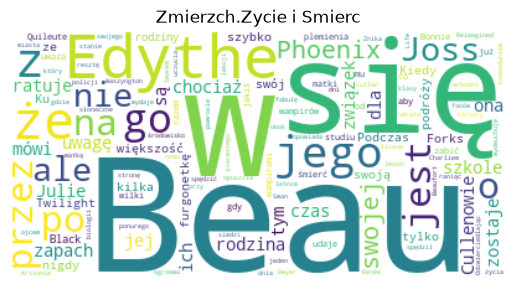

In [ ]:
for index ,row in document_df_pre.iterrows():
    wordcloud.generate(row["content"])
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(index.replace(".txt",""))
    plt.savefig(f"./wordclouds/pre{index.replace('txt','png')}")
    plt.close()

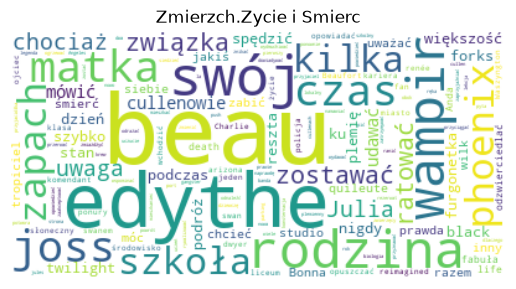

In [ ]:
for index ,row in document_df_post.iterrows():
    wordcloud.generate(row["content"])
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(index.replace(".txt",""))
    plt.savefig(f"./wordclouds/post{index.replace('txt','png')}")
    plt.close